In [1]:
%pylab inline
pylab.rcParams['figure.figsize'] = (12, 8)
import numpy as np
import jax.numpy as jnp
import jax
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import scipy.io as sio
import itertools

%run SINDy_PDE_FIND.py

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
# Importing the data

data = sio.loadmat('heat_linear_1d_data.mat')
u = real(data['u'])
x = real(data['x'][0])
t = real(data['t'][0,:])
dt = t[1]-t[0]
dx = x[2]-x[1]

Text(0.5, 0.5, 't')

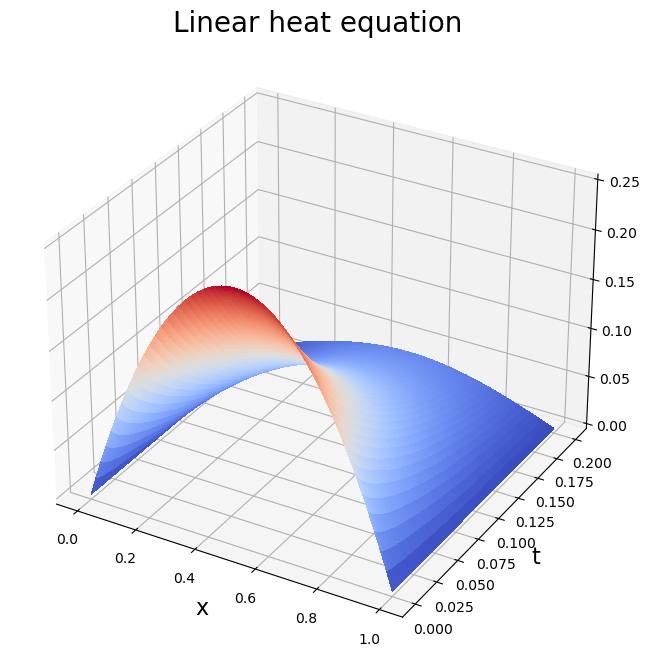

In [3]:
X, T = np.meshgrid(x, t)
fig1 = plt.figure()
ax = fig1.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, T, u.T, rstride=1, cstride=1, cmap=cm.coolwarm,
    linewidth=0, antialiased=False)
title('Linear heat equation', fontsize = 20)
xlabel('x', fontsize = 16)
ylabel('t', fontsize = 16)

In [3]:
Ut, R, rhs_des = build_linear_system(u, dt, dx, D=3, P=3, time_diff = 'FD', space_diff = 'FD')
['1'] + rhs_des[1:]

['1',
 'u',
 'u^2',
 'u^3',
 'u_{x}',
 'uu_{x}',
 'u^2u_{x}',
 'u^3u_{x}',
 'u_{xx}',
 'uu_{xx}',
 'u^2u_{xx}',
 'u^3u_{xx}',
 'u_{xxx}',
 'uu_{xxx}',
 'u^2u_{xxx}',
 'u^3u_{xxx}']

In [4]:
# R = R[:, 2:]
# rhs_des = rhs_des[2:]

In [4]:
# Solve with STRidge
w = TrainSTRidge(R,Ut,1e-2, 0.6)
print("PDE derived using STRidge")
print_pde(w, rhs_des)

PDE derived using STRidge
u_t = (-1.247332 +0.000000i)u
    + (0.868855 +0.000000i)u_{xx}
   


In [7]:
n, d = R.shape

In [5]:
def pde_sindy(theta, Ut, lam=0.1, eps=0.3, iterations=10):

    n, d = theta.shape

    w_best = np.linalg.lstsq(theta.T @ theta + lam*np.eye(d), theta.T @ Ut, rcond=None)[0]

    for k in range(iterations):
        s = abs(w_best) < eps # find coefficients less than eps ...
        w_best[s] = 0 # ... and set them to zero

    return w_best

In [6]:
w_best = pde_sindy(R, Ut, 0.9)

In [7]:
print_pde(w_best, rhs_des)

u_t = (-0.786167 +0.000000i)u
    + (0.892782 +0.000000i)u_{xx}
   


In [8]:
def cost_pde_sindy(w, theta, Ut, lam):
    '''Returns the cost of PDE SINDy for a given w coefficients vector
    Parameters- 
    w: Estimated w matrix for a given theta
    theta: Dictionary matrix
    Ut: Time derivative vector
    '''
    
    return jnp.linalg.norm(Ut - theta @ w)**2 + lam * jnp.linalg.cond(theta) * jnp.count_nonzero(w)

def grad_cost_pde_sindy(w, theta, Ut, lam):
    '''
    Returns the gradient of the cost function of PDE SINDy for a given w matrix
    Parameters-
    w: Estimated w matrix for a given theta
    theta: Dictionary matrix
    Ut: Time derivative vector
    '''
    grad_calc_psi = jax.grad(cost_pde_sindy)
    return grad_calc_psi(w, theta, Ut, lam)

In [9]:
# GD

loops = 10000
hw = 1e-7
f_vals_gd_w =[]
lam = 0.00001
w_gd = jnp.zeros((16, 1))

for i in range(loops):
    w_gd = w_gd - hw*grad_cost_pde_sindy(w_gd, R, Ut, lam)
    val = cost_pde_sindy(w_gd, R, Ut, lam)                                          # value of f at W
    f_vals_gd_w.append(val) 

for k in range(10):
    s = abs(w_gd) < 0.2 # find coefficients less than eps ...
    w_gd = w_gd.at[s].set(0)  # ... and set them to zero

c:\Users\tabis\Anaconda3\lib\site-packages\jax\_src\lax\lax.py:2660: ComplexWarning: Casting complex values to real discards the imaginary part
  x_bar = _convert_element_type(x_bar, x.aval.dtype, x.aval.weak_type)


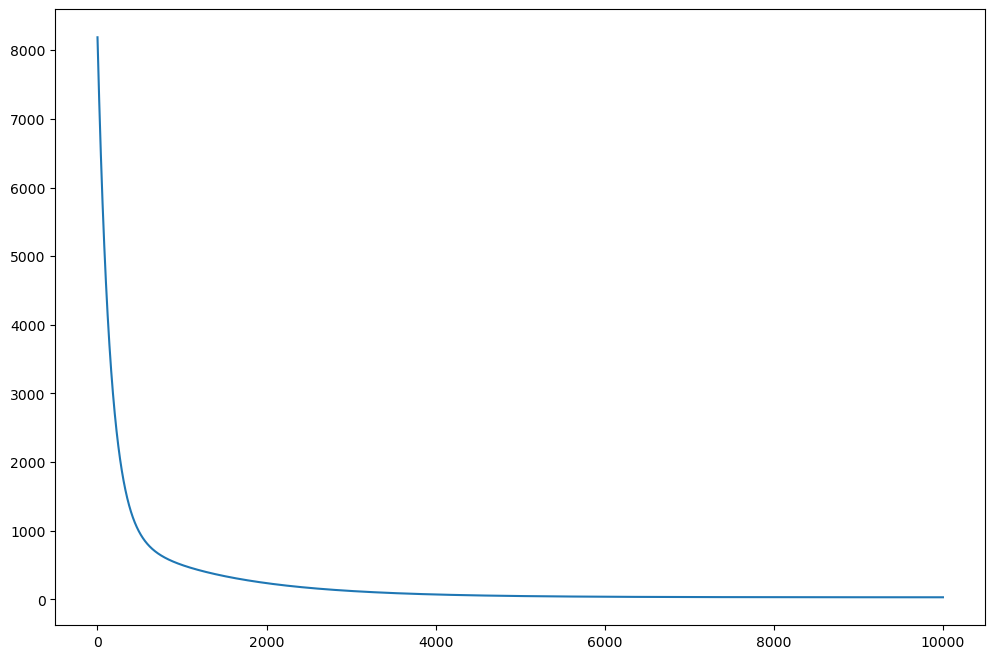

In [19]:
plt.plot(f_vals_gd_w)

In [10]:
print_pde(w_gd, rhs_des)

u_t = (0.937823 +0.000000i)u_{xx}
   


In [17]:
np.linalg.norm(w - w_best, 2)

0.4617899097206796

In [21]:
cost_pde_find_alg = cost_pde_sindy(w, R, Ut, 1e-5)
cost_pde_find_mine = cost_pde_sindy(w_best, R, Ut, 1e-5)
cost_pde_find_gd = cost_pde_sindy(w_gd, R, Ut, 1e-5)

In [22]:
print(cost_pde_find_alg)
print(cost_pde_find_mine)
print(cost_pde_find_gd)

10.688735
15.087513
37.149418


## For nonlinear heat equation

In [1]:
def build_new_theta(R, rhs_des, chi):

    #R_n = R.copy()
    R_n = jnp.zeros((R.shape[0], R.shape[1] + 2))
    R_n = R_n.at[:,:R.shape[1]].set(R)

    #rhs_des_n = rhs_des.copy()

    u_ind = rhs_des.index('u')
    ux_ind = rhs_des.index('u_{x}')
    uxx_ind = rhs_des.index('u_{xx}')
    u = R[:, u_ind]
    u_x = R[:, ux_ind]
    u_xx = R[:, uxx_ind]   
    
    
    exp_u = jnp.exp(chi * u)
    new_ux_term = exp_u * u_x**2
    new_uxx_term = exp_u * u_xx

    R_n = R_n.at[:, -2].set(new_ux_term)
    R_n = R_n.at[:, -1].set(new_uxx_term)
    

    #R_n[:, ux_ind] = new_ux_term
    #R_n[:, uxx_ind] = new_uxx_term 

    #rhs_des_n[ux_ind] = 'exp(Xu)(u_{x}^2)'
    #rhs_des_n[uxx_ind] = 'exp(Xu)(u_{xx})'

    return R_n


def pde_sindy(theta, Ut, lam=0.1, eps=0.3, iterations=10):

    n, d = theta.shape

    w_best = np.linalg.lstsq(theta.T @ theta + lam*np.eye(d), theta.T @ Ut, rcond=None)[0]

    for k in range(iterations):
        s = abs(w_best) < eps # find coefficients less than eps ...
        w_best[s] = 0 # ... and set them to zero

    return w_best


def cost_pde_sindy(w, chi, rhs_des, R, Ut, lam):
    '''Returns the cost of PDE SINDy for a given w coefficients vector
    Parameters- 
    w: Estimated w matrix for a given theta
    theta: Dictionary matrix
    Ut: Time derivative vector
    '''
    theta = build_new_theta(R, rhs_des, chi) 
    return jnp.linalg.norm(Ut - theta @ w)**2 + lam * jnp.linalg.cond(theta) # * jnp.count_nonzero(w)


def grad_cost_pde_sindy(w, chi, rhs_des, R, Ut, lam):
    '''
    Returns the gradient of the cost function of PDE SINDy for a given w matrix
    Parameters-
    w: Estimated w matrix for a given theta
    theta: Dictionary matrix
    Ut: Time derivative vector
    '''
    grad_calc_psi = jax.grad(cost_pde_sindy)
    return grad_calc_psi(w, chi, rhs_des, R, Ut, lam)


def grad_cost_pde_sindy_params(w, chi, rhs_des, R, Ut, lam):
    '''
    Returns the gradient of the cost function of PDE SINDy for a given w matrix
    Parameters-
    w: Estimated w matrix for a given theta
    theta: Dictionary matrix
    Ut: Time derivative vector
    '''
    grad_calc_psi_params = jax.grad(cost_pde_sindy, 1)
    return grad_calc_psi_params(w, chi, rhs_des, R, Ut, lam)


# GD

loops = 10000
hw = 1e-6
f_vals_gd_w =[]
lam = 0.0001
w_gd = jnp.zeros((len(rhs_des_n), 1))
p_gd = -0.5

for i in range(loops):
    w_gd = w_gd - hw*grad_cost_pde_sindy(w_gd, p_gd, rhs_des, Ut, lam)
    val = cost_pde_sindy(w_gd, p_gd, rhs_des, Ut, lam)                                          # value of f at W
    f_vals_gd_w.append(val)
    #p_gd = p_gd - hw*grad_cost_pde_sindy_params(w_gd, p_gd, rhs_des, Ut, lam)


# for k in range(10):
#     s = abs(w_gd) < 0.03 # find coefficients less than eps ...
#     w_gd = w_gd.at[s].set(0)  # ... and set them to zero